# Product Metrics & Onboarding–Retention Analysis
**Data: simulated** (see `src/simulate_product_data.py`). This notebook computes the core KPIs a weekly product dashboard would track (definitions in [`docs/kpi_dictionary.md`](../docs/kpi_dictionary.md)) and examines how onboarding completion relates to 7-day retention.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid"); FIG = Path("../figures"); FIG.mkdir(exist_ok=True)
rng = np.random.default_rng(42)

import statsmodels.formula.api as smf
u = pd.read_parquet("../data/simulated/users_clean.parquet")
ev = pd.read_parquet("../data/simulated/events_clean.parquet")
ev = ev.merge(u[["user_id", "signup_ts", "region"]], on="user_id")
ev["days_since_signup"] = (ev["event_ts"] - ev["signup_ts"]).dt.days
u["cohort_week"] = u["signup_ts"].dt.to_period("W-SUN").dt.start_time
print(f"{len(u):,} users · {len(ev):,} events")

40,000 users · 263,293 events


## 1. KPI overview

In [2]:
dau = ev[ev.event_type == "session_start"].groupby(ev.event_ts.dt.date)["user_id"].nunique()
adopt = ev[(ev.event_type == "feature_use") & (ev.days_since_signup < 7)].user_id.nunique() / len(u)
conv = ev[(ev.event_type == "purchase") & (ev.days_since_signup < 28)].user_id.nunique() / len(u)
kpi = pd.Series({"Avg DAU (Mar–Apr)": dau.loc[pd.Timestamp("2025-03-01").date():pd.Timestamp("2025-04-30").date()].mean(),
                 "Onboarding completion": u.onboarding_completed.mean(), "D1 retention": u.retained_d1.mean(),
                 "D7 retention": u.retained_d7.mean(), "Feature adoption (7d)": adopt, "Paid conversion (28d)": conv,
                 "ARPU (28d, USD)": ev[(ev.event_type == "purchase") & (ev.days_since_signup < 28)].revenue_usd.sum() / len(u)})
kpi.round(3)

Avg DAU (Mar–Apr)        1181.213
Onboarding completion       0.572
D1 retention                0.498
D7 retention                0.226
Feature adoption (7d)       0.455
Paid conversion (28d)       0.092
ARPU (28d, USD)             0.522
dtype: float64

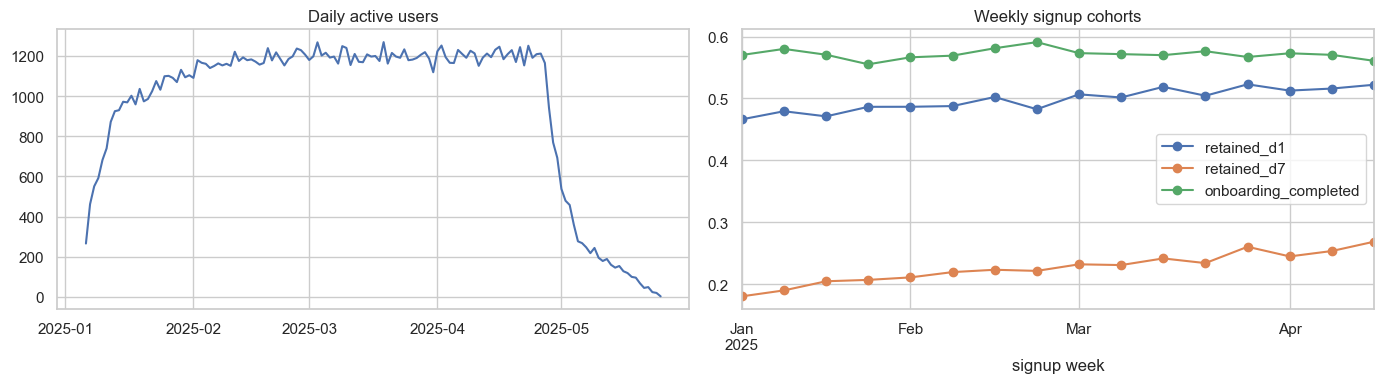

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
dau.plot(ax=ax[0], title="Daily active users"); ax[0].set_xlabel("")
coh = u.groupby("cohort_week")[["retained_d1", "retained_d7", "onboarding_completed"]].mean()
coh.plot(ax=ax[1], marker="o", title="Weekly signup cohorts"); ax[1].set_xlabel("signup week")
plt.tight_layout(); plt.savefig(FIG / "kpi_overview.png", dpi=130); plt.show()

## 2. KPI breakdown by channel and platform

In [4]:
seg = u.groupby("acquisition_channel").agg(users=("user_id", "size"), onboarding=("onboarding_completed", "mean"),
                                            d1=("retained_d1", "mean"), d7=("retained_d7", "mean"))
seg.round(3)

,users,onboarding,d1,d7
acquisition_channel,,,,
organic,15901,0.621,0.501,0.230
paid_social,12140,0.453,0.485,0.212
referral,6025,0.705,0.509,0.250
search,5934,0.547,0.505,0.221


## 3. Onboarding completion and 7-day retention

D7 retention: completed onboarding 26.9% vs not 17.0% (+9.9 pp)
Cohort cells: +10 pp onboarding completion ↔ +1.1 pp D7 retention (+5% relative), R²=0.05


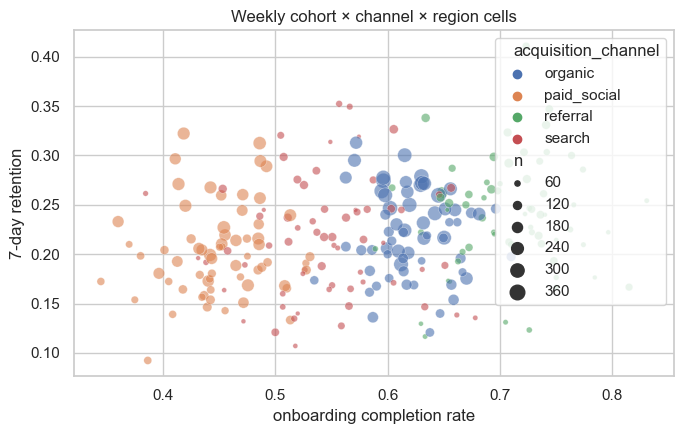

In [5]:
ob = u.groupby("onboarding_completed")["retained_d7"].mean()
print(f"D7 retention: completed onboarding {ob[True]:.1%} vs not {ob[False]:.1%} (+{(ob[True]-ob[False])*100:.1f} pp)")

# cohort-level view, as a dashboard would show it: weekly cohort × channel × region cells
cell = u.groupby(["cohort_week", "acquisition_channel", "region"]).agg(
    onboarding=("onboarding_completed", "mean"), d7=("retained_d7", "mean"), n=("user_id", "size")).reset_index()
cell = cell[cell.n >= 30]
slope = smf.wls("d7 ~ onboarding", data=cell, weights=cell.n).fit()
b = slope.params["onboarding"]
print(f"Cohort cells: +10 pp onboarding completion ↔ {b*0.10*100:+.1f} pp D7 retention "
      f"({b*0.10/u.retained_d7.mean():+.0%} relative), R²={slope.rsquared:.2f}")
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.scatterplot(data=cell, x="onboarding", y="d7", hue="acquisition_channel", size="n", sizes=(10, 120), alpha=0.6, ax=ax)
ax.set(xlabel="onboarding completion rate", ylabel="7-day retention", title="Weekly cohort × channel × region cells")
plt.tight_layout(); plt.savefig(FIG / "onboarding_vs_retention.png", dpi=130); plt.show()

### Controlling for confounders

In [6]:
u["d7"] = u.retained_d7.astype(int); u["onb"] = u.onboarding_completed.astype(int)
lpm = smf.ols("d7 ~ onb + C(acquisition_channel) + C(region) + C(platform) + C(cohort_week)", data=u).fit(cov_type="HC1")
logit = smf.logit("d7 ~ onb + C(acquisition_channel) + C(region) + C(platform)", data=u).fit(disp=0)
print(f"Linear probability model: onboarding → {lpm.params['onb']*100:+.1f} pp D7 retention "
      f"(95% CI {lpm.conf_int().loc['onb',0]*100:.1f}–{lpm.conf_int().loc['onb',1]*100:.1f})")
print(f"Logit odds ratio: {np.exp(logit.params['onb']):.2f}")

Linear probability model: onboarding → +9.7 pp D7 retention (95% CI 8.9–10.6)
Logit odds ratio: 1.78


## 4. Takeaways
- Users who complete onboarding retain at a much higher rate at day 7. The association survives controls for acquisition channel, region, platform and cohort week.
- At the cohort level the signal is much noisier: a 10 pp higher onboarding-completion rate goes with about +1 pp D7 retention (R² ≈ 0.05 across cohort cells). Aggregate dashboard views can hide a user-level relationship, so both levels are worth reporting. The user-level association is strong enough to justify an onboarding experiment.
- **This is observational:** motivated users may both finish onboarding and stay. The next step is a randomized test of an onboarding change (see notebook 01 for the test workflow), not a causal claim from this correlation.